### Synthetic Minority Over-sampling Technique (SMOTE)

**SMOTE** is an oversampling technique designed to handle class imbalance by generating **synthetic (artificial)** examples for the minority class rather than duplicating existing records.

#### How It Works:
1. **Identifies Neighbors:** For each sample in the minority class, it finds its $k$-nearest neighbors (typically $k = 5$) from the same class in the feature space.
2. **Feature Interpolation:** It selects one of these neighbors at random, calculates the difference vector between the two points, and multiplies it by a random number between $0$ and $1$.
3. **Generates Synthetic Samples:** The new synthetic instance is created along the line segment joining the selected data point and its neighbor.

$$\text{New Sample} = X_i + \lambda \times (X_{\text{zi}} - X_i) \quad \text{where } \lambda \in [0, 1]$$

#### Key Benefits & Considerations:
* **Reduces Overfitting:** Unlike simple random upsampling (sampling with replacement), SMOTE expands the decision boundary rather than forcing the model to memorize duplicate points.
* **Best Practice:** Apply SMOTE **only to the training set** after performing the train-test split to prevent data leakage into the evaluation data.

In [1]:
from sklearn.datasets import make_classification
x,y=make_classification(n_samples=1000,n_redundant=0,n_features=2,n_clusters_per_class=1,
                    weights=[0.90],random_state=12)

In [5]:
import pandas as pd
df1=pd.DataFrame(x,columns=['f1','f2'])
df2=pd.DataFrame(y,columns=['Target'])
df_final=pd.concat([df1,df2],axis=1)
df_final.head(5)

,f1,f2,Target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0


In [7]:
df_final['Target'].value_counts()

Target
0    900
1    100
Name: count, dtype: int64

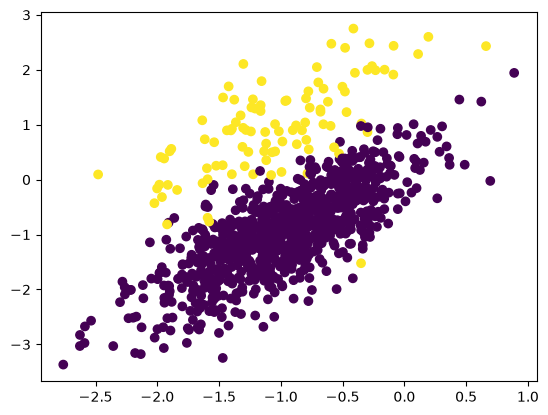

In [8]:
import matplotlib.pyplot as plt
plt.scatter(df_final['f1'],df_final['f2'],c=df_final['Target'])